In [ ]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score, confusion_matrix
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

In [ ]:
from google.colab import files
uploaded = files.upload()
df = pd.read_csv(list(uploaded.keys())[0], encoding='latin-1')
print(df.head())
print(df.columns)

Saving archive (1).zip to archive (1) (1).zip
     v1                                                 v2
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
Index(['v1', 'v2'], dtype='object')


In [ ]:
print("Columns:", df.columns.tolist())
print(df.head())
df = df.iloc[:, :2].copy()
df.columns = ['label', 'message']
df.dropna(subset=['label', 'message'], inplace=True)
df['label'] = df['label'].astype(str).str.lower().str.strip()
df['label'] = df['label'].replace({
    'ham': 0,
    'spam': 1
})
df = df[df['label'].isin(['0', '1', 0, 1])].copy()
df['label'] = df['label'].astype(int)
df.drop_duplicates(subset=['message'], inplace=True)
df = df.sample(n=min(2000, len(df)), random_state=42)
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^a-z0-9\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text
df['message'] = df['message'].apply(clean_text)
print("Dataset size:", len(df))
print(df['label'].value_counts())
print(df.head())

Columns: ['label', 'message']
Empty DataFrame
Columns: [label, message]
Index: []
Dataset size: 0
Series([], Name: count, dtype: int64)
Empty DataFrame
Columns: [label, message]
Index: []


In [21]:
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
print(df.head())
print(df.isnull().sum())

Dataset shape: (0, 2)
Columns: ['label', 'message']
Empty DataFrame
Columns: [label, message]
Index: []
label      0
message    0
dtype: int64


In [22]:
from google.colab import files
import pandas as pd
uploaded = files.upload()
filename = next(iter(uploaded))
df = pd.read_csv(filename, encoding='latin-1')
print("Columns:", df.columns.tolist())
print(df.head())
print("Shape:", df.shape)

Saving archive (1).zip to archive (1) (2).zip
Columns: ['v1', 'v2']
     v1                                                 v2
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
Shape: (5572, 2)


In [23]:
df = df[['v1', 'v2']].copy()
df.columns = ['label', 'message']
df = df.dropna(subset=['label', 'message'])
df['label'] = df['label'].astype(str).str.strip().str.lower()
df['message'] = df['message'].astype(str)
df = df[df['label'].isin(['ham', 'spam'])]
df['label'] = df['label'].map({'ham': 0, 'spam': 1})
df = df.drop_duplicates(subset=['message'])
df = df.sample(n=min(2000, len(df)), random_state=42)
print(df.shape)
print(df['label'].value_counts())
print(df.head())

(2000, 2)
label
0    1732
1     268
Name: count, dtype: int64
      label                                            message
1617      0                      Did u download the fring app?
2064      0  Pass dis to all ur contacts n see wat u get! R...
1272      0                                              Ok...
3020      0                     Am in film ill call you later.
3642      0  Sorry, left phone upstairs. OK, might be hecti...


In [24]:
df = df[['label', 'message']].copy()
df = df.dropna(subset=['label', 'message'])
df['label'] = df['label'].astype(str).str.strip().str.lower()
df['message'] = df['message'].astype(str)
df = df[df['label'].isin(['ham', 'spam'])]
df['label'] = df['label'].map({'ham': 0, 'spam': 1})
df = df.drop_duplicates(subset=['message'])
df = df.sample(n=min(2000, len(df)), random_state=42)
print(df.shape)
print(df['label'].value_counts())

(0, 2)
Series([], Name: count, dtype: int64)


In [25]:
X = df['message'].astype(str).values
y = df['label'].astype(int).values
print("Total messages:", len(X))
print("Labels:", set(y))

Total messages: 0
Labels: set()


In [27]:
model = Sequential([
    Embedding(input_dim=5000, output_dim=32, input_length=100),
    LSTM(32),
    Dropout(0.3),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [33]:
df = pd.read_csv(filename, encoding='latin-1')
df = df[['v1', 'v2']].copy()
df.columns = ['label', 'message']
df = df.dropna(subset=['label', 'message'])
df['label'] = df['label'].astype(str).str.strip().str.lower()
df['message'] = df['message'].astype(str)
df = df[df['label'].isin(['ham', 'spam'])]
df['label'] = df['label'].map({'ham': 0, 'spam': 1})
df = df.drop_duplicates(subset=['message'])
df = df.sample(n=min(2000, len(df)), random_state=42)
max_words = 5000
max_len = 100
tokenizer = Tokenizer(num_words=max_words, oov_token="<OOV>")
tokenizer.fit_on_texts(df['message'])
sequences = tokenizer.texts_to_sequences(df['message'])
X_padded = pad_sequences(sequences, maxlen=max_len, padding='post', truncating='post')
y = df['label'].values
X_train, X_test, y_train, y_test = train_test_split(X_padded, y, test_size=0.2, random_state=42)
history = model.fit(
    X_train, y_train,
    epochs=8,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/8
40/40 ━━━━━━━━━━━━━━━━━━━━ 6s 84ms/step - accuracy: 0.8383 - loss: 0.4872 - val_accuracy: 0.8906 - val_loss: 0.3457
Epoch 2/8
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 52ms/step - accuracy: 0.8562 - loss: 0.4245 - val_accuracy: 0.8906 - val_loss: 0.3521
Epoch 3/8
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.8562 - loss: 0.4159 - val_accuracy: 0.8906 - val_loss: 0.3459
Epoch 4/8
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.8562 - loss: 0.4208 - val_accuracy: 0.8906 - val_loss: 0.3471
Epoch 5/8
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - accuracy: 0.8562 - loss: 0.4200 - val_accuracy: 0.8906 - val_loss: 0.3583
Epoch 6/8
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.8562 - loss: 0.4202 - val_accuracy: 0.8906 - val_loss: 0.3479
Epoch 7/8
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.8562 - loss: 0.4153 - val_accuracy: 0.8906 - val_loss: 0.3478
Epoch 8/8
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - accuracy: 0.8562 - loss: 0.4170 - val_accuracy: 0.8906 - val_loss:

In [34]:
y_prob = model.predict(X_test)
y_pred = (y_prob >= 0.5).astype(int).flatten()
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
print("Model Evaluation")
print("-------------------------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-Score :", round(f1, 4))

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step
Model Evaluation
-------------------------
Accuracy : 0.8775
Precision: 0.0
Recall   : 0.0
F1-Score : 0.0


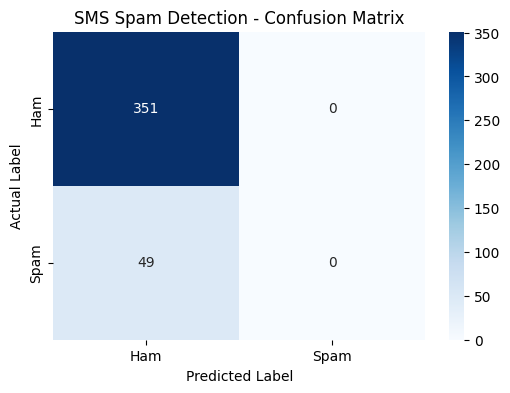

In [35]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('SMS Spam Detection - Confusion Matrix')
plt.show()

In [36]:
def predict_sms(message):
    cleaned = clean_text(message)
    sequence = tokenizer.texts_to_sequences([cleaned])
    padded = pad_sequences(
        sequence,
        maxlen=100,
        padding='post',
        truncating='post'
    )
    probability = model.predict(padded, verbose=0)[0][0]
    if probability >= 0.5:
        print("Message:", message)
        print("Prediction: SPAM")
    else:
        print("Message:", message)
        print("Prediction: HAM (Normal Message)")

    print("Spam Probability:", round(float(probability), 4))
    print()
predict_sms("Congratulations! You have won a free prize. Claim now!")
predict_sms("Hey, are you coming to college tomorrow?")
predict_sms("URGENT! You have won a cash reward. Call now!")
predict_sms("Hi, I will call you when I reach home.")

Message: Congratulations! You have won a free prize. Claim now!
Prediction: HAM (Normal Message)
Spam Probability: 0.1214

Message: Hey, are you coming to college tomorrow?
Prediction: HAM (Normal Message)
Spam Probability: 0.1214

Message: URGENT! You have won a cash reward. Call now!
Prediction: HAM (Normal Message)
Spam Probability: 0.1214

Message: Hi, I will call you when I reach home.
Prediction: HAM (Normal Message)
Spam Probability: 0.1214



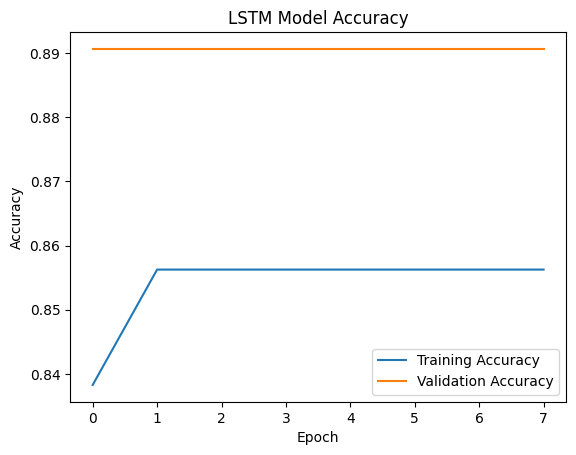

In [37]:
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('LSTM Model Accuracy')
plt.legend()
plt.show()